# Mapping patients onto a hexagon grid

Environmental and social data, such as the CHEL indicators, often come on a
grid of **H3 hexagons**, not on administrative areas like counties. To link a
patient to that kind of data, the patient's location needs a hexagon ID.

In this workshop's OMOP dataset the `location` table has an extra column,
`h3_id`: the H3 hexagon (resolution 3, about 12,000 km² each) that the
location's county was assigned to. This notebook uses it to:

1. look at the hexagon IDs in `location`,
2. count people per hexagon with one SQL query, and
3. draw those counts on a map using the hexagon shapes from a GeoPackage file.

The data is synthetic (CMS DE-SynPUF), and its locations are only counties, so
the map shows where the synthetic beneficiaries are coded, not real patients.

## Setup

The same pattern as the other notebooks: a `CDR` variable names the dataset and
`query()` returns a pandas DataFrame. We also use **geopandas**, which is pandas
with a geometry column.

In [1]:
# Works around a Workbench image bug that can stop the BigQuery client importing (see bq_env.py).
from bq_env import ensure_bigquery
ensure_bigquery()

try:
    import geopandas  # noqa: F401
except ImportError:
    %pip install -q geopandas

import os
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import pandas_gbq
from matplotlib.colors import LinearSegmentedColormap, LogNorm

PROJECT = os.environ["GOOGLE_CLOUD_PROJECT"]
CDR = f"{PROJECT}.synpuf_workshop"   # on All of Us: CDR = os.environ["WORKSPACE_CDR"]
HEXES_GPKG = Path("..") / "staging" / "data" / "h3_res3.gpkg"


def query(sql):
    # Run BigQuery SQL and return the result as a pandas DataFrame.
    return pandas_gbq.read_gbq(sql, project_id=PROJECT, progress_bar_type=None)


print("Querying", CDR)

Querying wb-glossy-cherry-7026.synpuf_workshop


## 1. Hexagon IDs in the location table

SynPUF locations are counties, coded by state and county. Each now also carries
the `h3_id` of its hexagon. Several counties can share one hexagon, and a few
locations have no hexagon at all: codes for "unknown county", or counties whose
codes changed since the crosswalk was made.

In [2]:
query(f'''
    SELECT location_id, state, county, h3_id
    FROM `{CDR}.location`
    ORDER BY location_id
    LIMIT 10
''')

,location_id,state,county,h3_id
0,1,MO,26950,832640fffffffff
1,2,PA,39230,832aa3fffffffff
2,3,PA,39280,832aa1fffffffff
3,4,CO,06290,832681fffffffff
4,5,WI,52590,832751fffffffff
5,6,NY,33400,832a10fffffffff
6,7,PA,39270,832aaefffffffff
7,8,MN,24680,832709fffffffff
8,9,MI,23810,832ab2fffffffff
9,10,AL,01570,8344ebfffffffff


In [3]:
coverage = query(f'''
    SELECT
      COUNT(*)                     AS persons,
      COUNTIF(l.h3_id IS NOT NULL) AS persons_with_hexagon,
      COUNT(DISTINCT l.h3_id)      AS hexagons_used
    FROM `{CDR}.person` p
    JOIN `{CDR}.location` l USING (location_id)
''')
coverage

,persons,persons_with_hexagon,hexagons_used
0,100000,98470,639


## 2. People per hexagon

Join `person` to `location` and count by `h3_id`. People without a hexagon can't
be placed on the map, so we leave them out.

In [4]:
counts = query(f'''
    SELECT l.h3_id, COUNT(*) AS persons
    FROM `{CDR}.person` p
    JOIN `{CDR}.location` l USING (location_id)
    WHERE l.h3_id IS NOT NULL
    GROUP BY l.h3_id
    ORDER BY persons DESC
''')
print(f"{len(counts):,} hexagons, {counts.persons.sum():,} people")
counts.head()

639 hexagons, 98,470 people


,h3_id,persons
0,832a10fffffffff,4052
1,8329a1fffffffff,2253
2,832664fffffffff,1971
3,832a13fffffffff,1724
4,832aa8fffffffff,1492


## 3. Hexagon shapes

The GeoPackage file holds one polygon per hexagon, keyed by the same `h3_id`.
Reading it with geopandas gives a table we can join like any other.

In [5]:
hexes = gpd.read_file(HEXES_GPKG)
print(f"{len(hexes):,} hexagons, coordinate system {hexes.crs}")
hexes.head()

ERROR 1: PROJ: proj_create_from_database: Open of /opt/conda/envs/jupyter/share/proj failed


934 hexagons, coordinate system EPSG:4269


,h3_id,geometry
0,832b8efffffffff,"POLYGON ((-75.55918 45.14799, -76.33587 44.798..."
1,832b8cfffffffff,"POLYGON ((-73.94423 45.19784, -74.73364 44.859..."
2,832b8afffffffff,"POLYGON ((-76.27781 44.16907, -77.03252 43.818..."
3,832b88fffffffff,"POLYGON ((-74.69774 44.22902, -75.46516 43.888..."
4,832aa6fffffffff,"POLYGON ((-78.50723 43.10557, -79.22728 42.744..."


## 4. Join and map

A left join keeps every hexagon, including those with nobody in them (count 0).
We map the contiguous US in an equal-area projection (EPSG:5070, the usual one
for US maps), so every hexagon appears at its true relative size.

Counts are very uneven from hexagon to hexagon, so the color scale is
logarithmic: each step darker means several times more people.

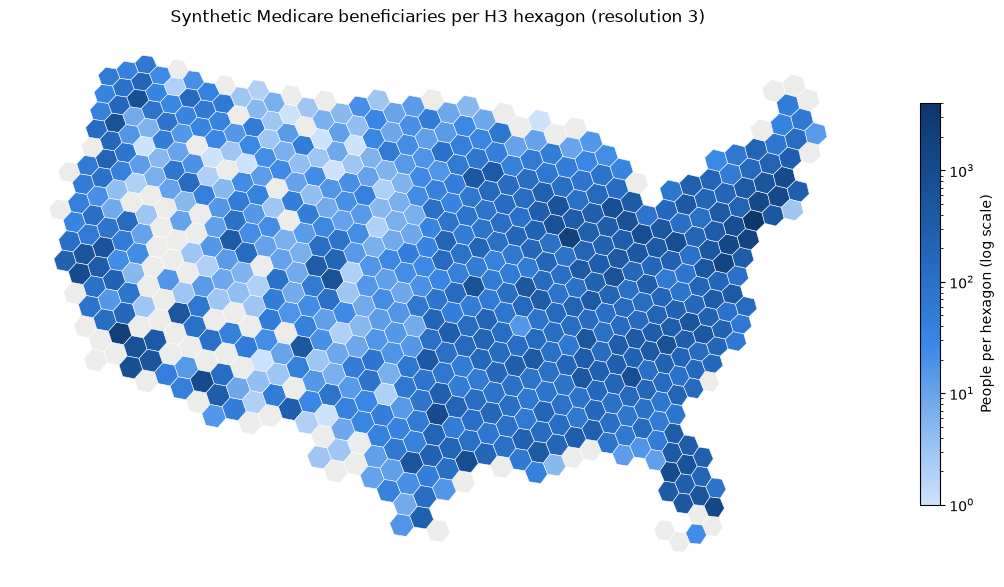

Mapped 97,768 people in 621 hexagons (gray: hexagons with nobody)


In [6]:
density = hexes.merge(counts, on="h3_id", how="left")
density["persons"] = density["persons"].fillna(0).astype(int)

# Contiguous US only (Alaska, Hawaii and territories would need their own insets),
# then reproject to an equal-area projection.
conus = density.cx[-125:-66, 24:50].to_crs(epsg=5070)

# Sequential single-hue ramp, light to dark.
blues = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

fig, ax = plt.subplots(figsize=(11, 7))
conus[conus.persons == 0].plot(ax=ax, color="#ececea", edgecolor="white", linewidth=0.4)
populated = conus[conus.persons > 0]
populated.plot(
    ax=ax, column="persons", cmap=blues, edgecolor="white", linewidth=0.4,
    norm=LogNorm(vmin=max(1, populated.persons.min()), vmax=populated.persons.max()),
    legend=True,
    legend_kwds={"label": "People per hexagon (log scale)", "shrink": 0.6},
)
ax.set_title("Synthetic Medicare beneficiaries per H3 hexagon (resolution 3)")
ax.set_axis_off()
plt.tight_layout()
plt.show()

print(f"Mapped {conus.persons.sum():,} people in {(conus.persons > 0).sum():,} hexagons "
      f"(gray: hexagons with nobody)")

## Things to notice, and next steps

- **Counties become points.** Each county is assigned a single hexagon, so a
  large county's people all land in one cell even if it spans several. Finer
  location data (addresses, ZIP codes) would spread people more realistically.
- **Unplaced people.** Compare `persons_with_hexagon` with `persons` above. Any
  linkage loses some records, and they're rarely missing at random.
- **Density is mostly population.** A count map largely shows where people
  live. For a health question, map a *rate* instead: for example, the share of
  people per hexagon with a diabetes diagnosis, using the concept sets from the
  survival notebook.
- **Linking environmental data.** Any table keyed by the same `h3_id` (air
  quality, heat, social indicators) joins to patients through `location`, exactly
  as the counts did here.